# Ancient Environmental Metagenomics (AEMG01)
## Day 4 · Part 1: Microbiome contamination correction – decontamination and source tracking

<a href="https://colab.research.google.com/github/NikolayOskolkov/AncientEnvironmentalMetagenomics/blob/main/notebooks/Day4_Decontamination_shortcut.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Prerequisites:** `Day1_setup_shortcut.ipynb` (`course_paths.json`) and `Day2_TaxonomicProfiling_shortcut.ipynb` (the abundance matrix `06_KRAKENUNIQ_ABUNDANCE_MATRIX/krakenuniq_abundance_matrix.txt`). Part 2 of today – contamination in **reference genomes** with the GENEX workflow – is in `Day4_GENEX_shortcut.ipynb`.

### Learning outcomes
After this practical you will be able to:

* name the main sources of contamination in ancient metagenomes,
* use **negative controls (blanks)** to flag contaminants – by eye, and statistically with **decontam**,
* estimate the endogenous content of samples with **cuperdec** cumulative-percent-decay curves,
* estimate which **environments** a sample's microbes come from with **SourceTracker** (and know the idea behind the database-free **decOM**),
* explain why decontamination is always a combination of evidence and never a fully automatic step.

<p align="center">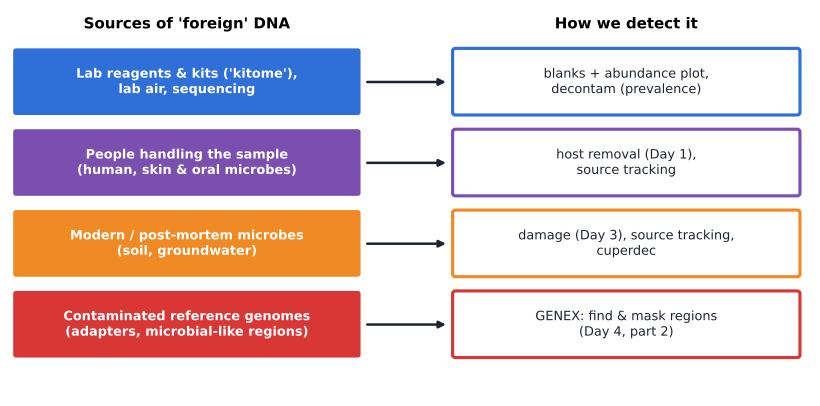<br><em>Sources of foreign DNA in ancient metagenomes and the approaches used to detect it.</em></p>

---
## Scientific background: why contamination is the central problem of ancient metagenomics

Modern contamination can severely bias ancient metagenomic analyses. Ancient samples usually contain very little authentic DNA, so even small amounts of modern DNA make up a large *fraction* of the reads. Large fractions of modern bacterial, animal or human DNA can lead to false biological and historical conclusions. Contamination can enter at every step:

* **in the ground** – modern soil and groundwater microbes colonise the sample (this DNA may itself be old, but it is *exogenous*: it entered *post-mortem* or after deposition),
* **during excavation and handling** – human DNA and human skin/oral microbes,
* **in the laboratory** – DNA in extraction kits, PCR reagents and water (the so-called **"kitome"**), lab air and surfaces, cross-contamination between samples,
* **in the reference databases** – reference genomes that themselves contain foreign sequences (Part 2 of today).

A large scientific literature is dedicated to this topic, with comprehensive lists of known contaminants:

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/contaminants_literature.png" width="700"><br><em>Literature on contaminant DNA, e.g. animal and bacterial DNA in PCR reagents.</em></p>

The most reliable defence is to sequence **negative controls**, so-called **blanks**: extraction and library blanks that go through every lab step without any sample. Whatever is found in a blank came from the lab, the reagents or the sequencer. The table below lists microbial genera frequently reported on blanks. Note that it may be rather **conservative**: besides well-known environmental contaminants such as *Burkholderia* and *Pseudomonas*, it also includes human-oral genera such as *Streptococcus*, which are less likely to be lab contaminants in, for example, a dental calculus study.

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/contaminants_list.png" width="650"><br><em>Microbial genera commonly detected in negative controls.</em></p>

An organism found on a blank is usually considered **less likely to be endogenous**, and is sometimes excluded altogether. Despite attempts to automate this (we will try several today), **decontamination remains a careful, partly manual process**: each candidate should be examined in several contexts – blanks, damage (Day 3), expected ecology – before it is accepted as ancient and endogenous.

---
## 1. Session setup

### 1.1 Install conda
`condacolab.install()` restarts the kernel – the *"session crashed"* message is expected; continue with the next cell.

In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()

In [ ]:
import shutil, sys
mamba = shutil.which("mamba")
print("Python :", sys.executable)
print("mamba  :", mamba or "NOT FOUND")
assert mamba, "conda/mamba is not installed – run the condacolab.install() cell above and wait for the restart"
!mamba --version

### 1.2 Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### 1.3 Install today's software

Today is mostly **R**: the course material uses the R packages **decontam** (Bioconductor), **cuperdec** (CRAN) and your own copy of the **SourceTracker** R script. We put R and these packages into a dedicated conda environment called `renv`, so that they cannot conflict with Colab's own R or Python:

| Package | Source | Used for |
|---|---|---|
| `r-base` | conda-forge | R itself (`Rscript`) |
| `r-ggplot2`, `r-dplyr`, `r-tidyr`, `r-purrr`, `r-readr`, `r-tibble`, `r-magrittr`, `r-viridis` | conda-forge | data handling and plotting (also required by cuperdec) |
| `bioconductor-decontam` | Bioconda | statistical identification of contaminants |
| `cuperdec` | CRAN, installed from R | cumulative percent decay curves |

`mamba create -n renv …` creates the environment. In the next cell, `install.packages("cuperdec", repos = …)` downloads cuperdec from CRAN into that environment's R library. We run R with `PATH=$ENVS/renv/bin:$PATH Rscript …`, i.e. with the `renv` environment's R first on the `PATH` for that command.

Installation takes ~5 minutes; logs go to `/content/install_*.log`.

In [ ]:
!mamba install -y -q -c conda-forge pandas > /content/install_base.log 2>&1
!mamba create -y -q -n renv -c conda-forge -c bioconda r-base r-ggplot2 r-dplyr r-tidyr r-purrr r-readr r-tibble r-magrittr r-viridis bioconductor-decontam > /content/install_renv.log 2>&1
print("done")

### 1.4 Paths and input files

All helper files of today's practical are in the shared folder **`$SHARE/scripts`**:

| File | Content |
|---|---|
| `blank_krakenuniq_abundance_matrix.txt` | KrakenUniq abundance matrix of the **negative controls** (column names contain `control`) |
| `otus_hmp.txt`, `meta_hmp.txt` | abundances and metadata of **Human Microbiome Project** samples (the *sources* for SourceTracker) |
| `SourceTracker.r` | the SourceTracker R code |
| `krakenuniq_abundance_matrix.txt` | the course's KrakenUniq matrix for the 10 samples (used if your own from Day 2 is missing) |

For the samples we use **your own** abundance matrix from Day 2 when it exists. All results go to the folder `10_DECONTAMINATION` in your working directory. (Folders `08_ASSEMBLY` and `09_ASSEMBLY_QC` are reserved for Day 5.)

`ENVS` is the folder containing the conda environments; we look it up with `conda info --base`.

In [ ]:
import os, json, glob, subprocess

WORKDIR = "/content/drive/MyDrive/AEMG01"            # your own working folder (Day1_setup)
SHARE = json.load(open(f"{WORKDIR}/course_paths.json"))["SHARE"]
SCRIPTS = f"{SHARE}/scripts"
ENVS = subprocess.run(["conda", "info", "--base"], capture_output=True, text=True).stdout.strip() + "/envs"
OUT = f"{WORKDIR}/10_DECONTAMINATION"
os.makedirs(OUT, exist_ok=True)

SAMPLES_MATRIX = f"{WORKDIR}/06_KRAKENUNIQ_ABUNDANCE_MATRIX/krakenuniq_abundance_matrix.txt"
if not os.path.exists(SAMPLES_MATRIX):
    SAMPLES_MATRIX = f"{SCRIPTS}/krakenuniq_abundance_matrix.txt"
BLANKS_MATRIX = f"{SCRIPTS}/blank_krakenuniq_abundance_matrix.txt"

os.environ.update(WORKDIR=WORKDIR, SHARE=SHARE, SCRIPTS=SCRIPTS, ENVS=ENVS, OUT=OUT,
                  SAMPLES_MATRIX=SAMPLES_MATRIX, BLANKS_MATRIX=BLANKS_MATRIX,
                  THREADS=str(os.cpu_count()))
os.chdir(WORKDIR)

for k in ["SCRIPTS", "ENVS", "OUT", "SAMPLES_MATRIX", "BLANKS_MATRIX"]:
    print(f"{k:15s}: {os.environ[k]}")
print()
for f in ["blank_krakenuniq_abundance_matrix.txt", "otus_hmp.txt", "meta_hmp.txt", "SourceTracker.r"]:
    print(("✅ " if os.path.exists(f"{SCRIPTS}/{f}") else "❌ ") + f)

Install cuperdec from CRAN into the `renv` environment and check that R and all packages load. `Rscript -e '…'` runs a one-line R command; `suppressMessages(library(x))` loads a package quietly and fails loudly if it is missing.

In [ ]:
%%bash
export PATH=$ENVS/renv/bin:$PATH
Rscript -e 'if (!requireNamespace("cuperdec", quietly = TRUE)) install.packages("cuperdec", repos = "https://cloud.r-project.org")' > /content/install_cuperdec.log 2>&1
Rscript -e 'for (p in c("decontam", "cuperdec", "ggplot2", "dplyr", "magrittr")) suppressMessages(library(p, character.only = TRUE)); cat(R.version.string, "– all packages loaded\n")'

Helpers: `show_file()` displays HTML/PDF files in an embedded frame (as on previous days), `show_png()` displays an image written by R.

In [ ]:
import socket, time
from google.colab import output, files
from IPython.display import HTML, Image, display, Markdown
import pandas as pd, numpy as np, matplotlib.pyplot as plt

PORT = 8000
def _server_running(port=PORT):
    with socket.socket() as s:
        return s.connect_ex(("localhost", port)) == 0

def show_file(path, height=700):
    """Show an HTML or PDF file (absolute path under /content) in an embedded frame."""
    if not _server_running():
        subprocess.Popen(["python", "-m", "http.server", str(PORT), "--directory", "/content"],
                         stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        time.sleep(2)
    output.serve_kernel_port_as_iframe(PORT, path="/" + os.path.relpath(path, "/content"), height=height)

def show_png(path, width=800):
    display(Image(filename=path, width=width))

os.environ["MPLBACKEND"] = "Agg"   # for programs started from %%bash cells (see Day 3)
os.makedirs("/content/r", exist_ok=True)
print("Helpers ready")

---
## 2. Negative controls: which organisms are found in the blanks?

### 2.1 A first look at the data

Let's load both abundance matrices (rows = species, columns = samples or blanks, values = KrakenUniq reads after the depth/breadth filter of Day 2) and see which species are present in the blanks.

In [ ]:
samples  = pd.read_csv(SAMPLES_MATRIX, sep="\t", index_col=0)
controls = pd.read_csv(BLANKS_MATRIX,  sep="\t", index_col=0)
print("samples :", samples.shape, list(samples.columns))
print("controls:", controls.shape, list(controls.columns))
print("species in both tables:", len(samples.index.intersection(controls.index)))
controls[controls.sum(axis=1) > 0].sort_values(controls.columns[0], ascending=False).head(15)

### 2.2 Abundance in samples vs abundance in blanks

The simplest and very effective approach: compute for each organism its **mean abundance across real samples** and its **mean abundance across blanks**, and plot one against the other on a log scale. Organisms that are abundant in **both** stand out as likely contaminants (red in the plot).

The R code from the course, explained step by step:

| R code | Meaning |
|---|---|
| `read.delim(file, header=TRUE, row.names=1, check.names=FALSE, sep="\t")` | read a tab-separated table; first column = row names (species); keep column names as they are |
| `merge(samples, controls, all=TRUE, by="row.names")` | join the two tables by species name; `all=TRUE` keeps species present in only one of them (*outer join*) |
| `df[is.na(df)] <- 0` | species missing from one table get abundance 0 |
| `grepl("control", colnames(df))` | TRUE for columns whose name contains "control" → splits the table into blanks and true samples |
| `log10(rowMeans(x) + 1)` | mean abundance per species, log-transformed (+1 avoids log(0)) |
| `(y > 1) & (x > 1)` | species with mean > ~10 reads in **both** groups → highlighted in red |

We write the R code to a file with `%%writefile` and run it with `Rscript`. The plot is saved as a PNG and displayed.

> 📝 Note for the original course text: in a few R lines of `exercises.md` the formula operator `~` (as in `plot(y ~ x)`) was accidentally replaced by `/content/drive/MyDrive` during a search-and-replace of paths. The code below uses the correct `~`.

In [ ]:
%%writefile /content/r/blank_vs_samples.R
samples  <- read.delim(Sys.getenv("SAMPLES_MATRIX"), header = TRUE, row.names = 1, check.names = FALSE, sep = "\t")
controls <- read.delim(Sys.getenv("BLANKS_MATRIX"),  header = TRUE, row.names = 1, check.names = FALSE, sep = "\t")

df <- merge(samples, controls, all = TRUE, by = "row.names")
rownames(df) <- df$Row.names; df$Row.names <- NULL; df[is.na(df)] <- 0

true_sample      <- subset(df, select = colnames(df)[!grepl("control", colnames(df))])
negative_control <- subset(df, select = colnames(df)[ grepl("control", colnames(df))])

x <- log10(rowMeans(negative_control) + 1)
y <- log10(rowMeans(true_sample) + 1)
hit <- (y > 1) & (x > 1)

png(file.path(Sys.getenv("OUT"), "blank_vs_samples.png"), width = 1000, height = 800, res = 120)
plot(y ~ x, xlab = "Log10 ( Negative controls )", ylab = "Log10 ( True samples )",
     main = "Organism abundance in true samples vs. negative controls", pch = 19, col = "blue")
points(y[hit] ~ x[hit], pch = 19, col = "red")
text(y[hit] ~ x[hit], labels = rownames(true_sample)[hit], pos = 4, cex = 0.7)
dev.off()

write.table(data.frame(organism = rownames(df), log10_mean_samples = y, log10_mean_blanks = x, flagged = hit),
            file.path(Sys.getenv("OUT"), "blank_vs_samples.tsv"), sep = "\t", quote = FALSE, row.names = FALSE)
cat("organisms flagged as likely contaminants:", sum(hit), "\n")

In [ ]:
%%bash
PATH=$ENVS/renv/bin:$PATH Rscript /content/r/blank_vs_samples.R

In [ ]:
show_png(f"{OUT}/blank_vs_samples.png", 700)

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/blank_decontam.png" width="560"><br><em>Expected result from the course material: red points are abundant in both true samples and negative controls.</em></p>

The same data as an **interactive** plot: hover over a point to see the organism. (plotly renders as an HTML widget inside the notebook.)

In [ ]:
bvs = pd.read_csv(f"{OUT}/blank_vs_samples.tsv", sep="\t")
try:
    import plotly.express as px
    fig = px.scatter(bvs, x="log10_mean_blanks", y="log10_mean_samples", color="flagged",
                     hover_name="organism", color_discrete_map={True: "red", False: "blue"},
                     labels={"log10_mean_blanks": "log10(mean in blanks + 1)",
                             "log10_mean_samples": "log10(mean in samples + 1)"},
                     title="Samples vs negative controls (hover for names)", width=800, height=600)
    fig.show()
except ImportError:
    print("plotly not available – see the static plot above")
display(bvs[bvs.flagged].sort_values("log10_mean_blanks", ascending=False))

❓ **Questions**
1. Which organisms are flagged? Are they known laboratory contaminants (compare with the list above)?
2. Is *Yersinia pestis* found in the blanks?
3. The threshold `> 1` (~10 reads) is arbitrary. What happens to an organism that is very abundant in samples but present at low levels in blanks? Would you remove it?

---
## 3. Statistical decontamination with decontam

[**decontam**](https://microbiomejournal.biomedcentral.com/articles/10.1186/s40168-018-0605-2) (Davis et al. 2018) offers two simple statistical tests for whether a detected organism is a contaminant.

### 3.1 The frequency method (needs DNA concentrations)
This method requires DNA quantification of every sample (e.g. PicoGreen fluorescence or qPCR). The idea: contaminant DNA is present in approximately **equal and low amounts** in every sample, while the amount of sample DNA varies widely. The *relative* frequency of a contaminant is therefore **inversely proportional to the total DNA concentration** (red line below), while the frequency of a genuine organism does not depend on it (blue line).

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/decontam.png" width="640"><br><em>decontam frequency method: contaminant frequency decreases with total DNA concentration (red); non-contaminants do not (blue).</em></p>

We have no DNA concentrations for our samples, so we use the second method.

### 3.2 The prevalence method (needs negative controls)

<p align="center">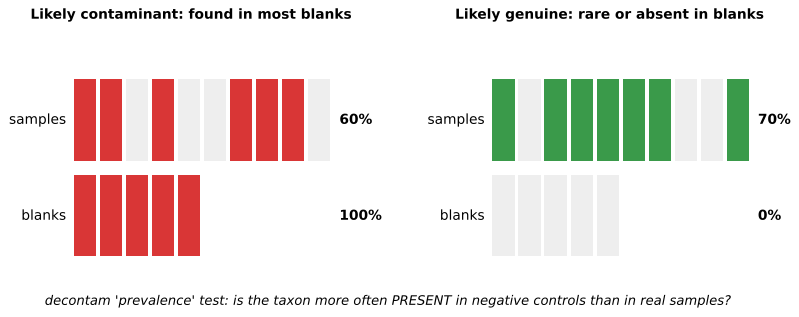</p>

The **prevalence** of a taxon is the fraction of samples in which it is **present** (abundance > 0). A contaminant is expected to be **more prevalent in negative controls** than in true samples. For every taxon decontam compares presence/absence in samples and blanks with a chi-square / Fisher test and reports a score `p`; taxa with `p < threshold` are called contaminants. With `threshold = 0.5` a taxon is flagged when it is more prevalent in blanks than in samples.

| R code | Meaning |
|---|---|
| `t(as.matrix(df))` | decontam expects **samples in rows**, taxa in columns – so we transpose |
| `neg <- grepl("control", rownames(ps))` | logical vector: which rows are negative controls |
| `isContaminant(ps, neg = neg, method = "prevalence", threshold = 0.5)` | run the test |
| `res$contaminant` | TRUE / FALSE per taxon |

In [ ]:
%%writefile /content/r/decontam_prevalence.R
suppressMessages(library(decontam))
samples  <- read.delim(Sys.getenv("SAMPLES_MATRIX"), header = TRUE, row.names = 1, check.names = FALSE, sep = "\t")
controls <- read.delim(Sys.getenv("BLANKS_MATRIX"),  header = TRUE, row.names = 1, check.names = FALSE, sep = "\t")
df <- merge(samples, controls, all = TRUE, by = "row.names")
rownames(df) <- df$Row.names; df$Row.names <- NULL; df[is.na(df)] <- 0

ps  <- t(as.matrix(df))                       # samples x taxa
neg <- grepl("control", rownames(ps))
cat("true samples:", sum(!neg), " negative controls:", sum(neg), "\n")

res <- isContaminant(ps, neg = neg, method = "prevalence", threshold = 0.5)
res$prevalence_samples <- colSums(ps[!neg, , drop = FALSE] > 0) / sum(!neg)
res$prevalence_blanks  <- colSums(ps[ neg, , drop = FALSE] > 0) / sum(neg)

write.table(cbind(organism = rownames(res), res), file.path(Sys.getenv("OUT"), "decontam_prevalence.tsv"),
            sep = "\t", quote = FALSE, row.names = FALSE)
cat("contaminants identified:", sum(res$contaminant, na.rm = TRUE), "of", nrow(res), "taxa\n")

In [ ]:
%%bash
PATH=$ENVS/renv/bin:$PATH Rscript /content/r/decontam_prevalence.R

In [ ]:
dc = pd.read_csv(f"{OUT}/decontam_prevalence.tsv", sep="\t")
display(dc[dc.contaminant == True][["organism", "prevalence_samples", "prevalence_blanks", "p"]]
        .sort_values("p"))

jit = np.random.default_rng(0).normal(0, 0.012, (len(dc), 2))
plt.figure(figsize=(6.5, 5.5))
plt.scatter(dc.prevalence_blanks + jit[:, 0], dc.prevalence_samples + jit[:, 1], s=25, alpha=0.7,
            c=np.where(dc.contaminant == True, "#D93636", "#2E6FD8"))
plt.plot([0, 1], [0, 1], ls=":", c="grey")
plt.xlabel("prevalence in negative controls"); plt.ylabel("prevalence in true samples")
plt.title("decontam prevalence test (red = contaminant)"); plt.show()

# compare with the simple abundance-based approach of Section 2
both = set(dc[dc.contaminant == True].organism) & set(bvs[bvs.flagged].organism)
print("flagged by both approaches:", sorted(both))

❓ **Questions**
1. How many taxa does decontam call contaminants? Do they agree with the abundance plot of Section 2?
2. With only a few negative controls, what is the smallest difference in prevalence the test can detect? Why do decontam's authors recommend sequencing **many** blanks?
3. The prevalence method uses presence/absence only. What information does it ignore?

---
## 4. Contaminated reference databases and other approaches

### 4.1 Contamination can also be in the reference
In addition to reagents and lab contaminants, **reference databases** can be contaminated too. A well-known example: when screening sedimentary ancient DNA, the common carp *Cyprinus carpio* often appears if adapter trimming was not fully successful, because the *C. carpio* reference genome in NCBI contains a large fraction of **Illumina adapter** sequence. Its appearance could falsely suggest a lake or river at the excavation site.

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/carpio.png" width="600"></p>
More generally, eukaryotic reference genomes contain **microbial-like regions**, so bacterial reads from a sediment can be mis-assigned to plants or animals. Detecting and masking such regions with the **GENEX** workflow is the topic of **`Day4_GENEX_shortcut.ipynb`**.

### 4.2 Recentrifuge
[**Recentrifuge**](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1006967) (Martí 2019) analyses the outputs of classifiers such as Centrifuge, Kraken or CLARK. Given **negative controls**, it subtracts contaminant taxa from the samples in a robust way that takes the classification **score** of every read and the taxonomic tree into account, and it produces interactive, Krona-like HTML reports for comparing samples. It needs per-read classification outputs for the blanks (not only abundance tables), which we don't have for our simulated blanks, so we only discuss it here.

### 4.3 How much of each sample is endogenous? cuperdec
If we know what microbial community to *expect* (e.g. an oral community in dental calculus), we can ask how much of each sample matches it. [**cuperdec**](https://github.com/jfy133/cuperdec) (Fellows Yates et al. 2021) ranks the taxa of each sample by abundance and, in an **expanding window** (top 1, top 2, top 3 … taxa), computes the percentage of taxa found in a reference list of taxa typical of the target source (an *isolation source database*). The resulting **Cumulative Percent Decay** curves stay high for well-preserved samples, whose most abundant taxa are typical of the source; they drop quickly for samples dominated by environmental or contaminant taxa. A threshold (here 50 %) separates samples to keep from samples to discard.

| R code | Meaning |
|---|---|
| `data(cuperdec_database_ex)` | an example isolation-source database shipped with cuperdec |
| `load_database(…, target = "oral")` | mark taxa annotated as **oral** as "target" |
| `load_taxa_table(file)` | read the abundance matrix (first column `Taxon`, one column per sample) and convert it to long format (Taxon, Sample, Count) |
| `calculate_curve(taxatable, database)` | compute the cumulative percent decay curve of every sample |
| `simple_filter(curves, percent_threshold = 50)` | samples whose curve never reaches 50 % fail |
| `plot_cuperdec(curves, metadata, filter_result)` | plot the curves (failed samples in red) |

> ⚠️ Our samples are *simulated* and not dental calculus, and the example database is small – treat the result as a demonstration of the method, not as a biological result.

**Preparing the input.** The abundance matrix from Day 2 was written by R with row names, so its header line has one field **fewer** than the data lines (there is no name above the species column). R's `read.delim()` copes with that, but cuperdec reads tables with the `readr` package, which then shifts the columns and fails (*"Can't combine … <double> and … <character>"*). We therefore write a clean copy with pandas: an explicit first column called `Taxon`, numeric counts only, and short sample names.

In [ ]:
m = pd.read_csv(SAMPLES_MATRIX, sep="\t", index_col=0)       # pandas handles the shorter header line
m = m.apply(pd.to_numeric, errors="coerce").fillna(0)
m.columns = [c.split(".")[0] for c in m.columns]               # sample10.krakenuniq.output.filtered -> sample10
m.index.name = "Taxon"
CUPERDEC_MATRIX = f"{OUT}/abundance_matrix_for_cuperdec.tsv"
m.to_csv(CUPERDEC_MATRIX, sep="\t")
os.environ["CUPERDEC_MATRIX"] = CUPERDEC_MATRIX
print(m.shape); m.head(3)

In [ ]:
%%writefile /content/r/cuperdec.R
suppressMessages({library("cuperdec"); library("magrittr"); library("dplyr"); library("ggplot2")})

data(cuperdec_database_ex)
database <- load_database(cuperdec_database_ex, target = "oral")

taxatable <- load_taxa_table(Sys.getenv("CUPERDEC_MATRIX"))
metadata  <- as_tibble(data.frame(Sample = unique(taxatable$Sample), Sample_Source = "Oral"))

curves        <- calculate_curve(taxatable, database = database)
filter_result <- simple_filter(curves, percent_threshold = 50)
print(filter_result)

p <- plot_cuperdec(curves, metadata = metadata, filter_result)
ggsave(file.path(Sys.getenv("OUT"), "cuperdec.png"), p, width = 8, height = 5, dpi = 120)

In [ ]:
%%bash
PATH=$ENVS/renv/bin:$PATH Rscript /content/r/cuperdec.R

In [ ]:
show_png(f"{OUT}/cuperdec.png", 750)

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/cuperdec2.png" width="620"><br><em>Example from the course material: each curve is one sample; red curves have high contamination and little endogenous content.</em></p>
❓ Which samples would cuperdec suggest discarding? Why would this test be meaningless if you chose the wrong target source?

---
## 5. Microbial source tracking

Besides comparing with blanks, we can ask: **which environments do the microbes in a sample most likely come from?** A dental calculus sample should look *oral*; a skeleton contaminated by soil would show a large *soil* fraction; a sample handled without gloves may show *skin* microbes.

### 5.1 SourceTracker
[**SourceTracker**](https://www.nature.com/articles/nmeth.1650) (Knights et al. 2011) is a **Bayesian** method. It treats every sample of unknown origin – a **sink** – as a **mixture** of communities from known environments – the **sources** (e.g. human gut, oral, skin, soil) – plus an **Unknown** source. Using Gibbs sampling it estimates the **proportion** of the sink that comes from each source. Conceptually it is related to mixture-model clustering, with the mixture components learned from labelled source samples.

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/SourceTracker.png" width="650"><br><em>SourceTracker: a sink community is modelled as a mixture of known source communities plus an unknown source.</em></p>

SourceTracker was developed for 16S rRNA data, but works with shotgun abundance tables too; its metagenomic extension is **mSourceTracker**, and **FEAST** is a faster, more scalable alternative. As **sources** we use samples from the **Human Microbiome Project (HMP)** with known body sites; as **sinks**, our 10 samples.

**Preparing the data** (R code from the course, step by step):

| R code | Meaning |
|---|---|
| `read.delim("otus_hmp.txt", …)`, `read.delim("meta_hmp.txt", …)` | HMP abundances (taxa × samples) and metadata (`Env` = body site, `SourceSink` = "source") |
| `merge(otus_hmp, otus_sink, all = TRUE, by = "row.names")` | one table with HMP and our samples; taxa missing in one dataset get 0 |
| `meta_sink <- data.frame(ID = …, Env = "Unknown", SourceSink = "sink")` | metadata rows for our samples |
| `otus <- t(as.matrix(otus))` | SourceTracker wants **samples in rows** |
| `otus[otus > 0] <- 1` | convert to **presence/absence**, which makes HMP (sequenced and profiled differently) and our KrakenUniq table comparable |
| `metadata[Env != "Vaginal", ]` | drop vaginal samples – an implausible source for our samples |
| `intersect(rownames(metadata), rownames(otus))` | keep samples present in both tables, in the same order |

**Training and prediction:**

| R code | Meaning |
|---|---|
| `source("SourceTracker.r")` | load the SourceTracker functions (your copy in `$SHARE/scripts`) |
| `train.ix`, `test.ix` | row numbers of sources and sinks |
| `sourcetracker(otus[train.ix,], envs[train.ix])` | learn the source communities |
| `predict(st, otus[test.ix,], alpha1 = 0.001, alpha2 = 0.001)` | estimate source proportions of every sink; `alpha1`, `alpha2` are priors controlling how much the sink may deviate from the known sources and from the unknown source |

The Gibbs sampling takes a few minutes.

In [ ]:
%%writefile /content/r/sourcetracker.R
scripts <- Sys.getenv("SCRIPTS"); out <- Sys.getenv("OUT")

otus_hmp <- read.delim(file.path(scripts, "otus_hmp.txt"), header = TRUE, row.names = 1, sep = "\t")
meta_hmp <- read.delim(file.path(scripts, "meta_hmp.txt"), header = TRUE, row.names = 1, sep = "\t")

otus_sink <- read.delim(Sys.getenv("SAMPLES_MATRIX"), header = TRUE, row.names = 1, sep = "\t")
otus <- merge(otus_hmp, otus_sink, all = TRUE, by = "row.names")
rownames(otus) <- otus$Row.names; otus$Row.names <- NULL; otus[is.na(otus)] <- 0
meta_sink <- data.frame(ID = colnames(otus_sink), Env = "Unknown", SourceSink = "sink")
rownames(meta_sink) <- meta_sink$ID; meta_sink$ID <- NULL
metadata <- rbind(meta_hmp, meta_sink)

otus <- as.data.frame(t(as.matrix(otus)))
otus[otus > 0] <- 1; otus <- otus[rowSums(otus) != 0, ]
metadata <- metadata[as.character(metadata$Env) != "Vaginal", ]; envs <- metadata$Env
common.sample.ids <- intersect(rownames(metadata), rownames(otus))
otus <- otus[common.sample.ids, ]; metadata <- metadata[common.sample.ids, ]; envs <- metadata$Env
cat("sources:", sum(metadata$SourceSink == "source"), " sinks:", sum(metadata$SourceSink == "sink"), "\n")
print(table(envs[metadata$SourceSink == "source"]))

# Train SourceTracker on sources (HMP) and run predictions on sinks
source(file.path(scripts, "SourceTracker.r"))
train.ix <- which(metadata$SourceSink == "source")
test.ix  <- which(metadata$SourceSink == "sink")
st <- sourcetracker(otus[train.ix, ], envs[train.ix])
results <- predict(st, otus[test.ix, ], alpha1 = 0.001, alpha2 = 0.001)

props <- results$proportions
if ("Oral" %in% colnames(props)) props <- props[order(-props[, "Oral"]), ]
write.table(props, file.path(out, "sourcetracker_proportions.tsv"), sep = "\t", quote = FALSE)

# Plot SourceTracker inference as a barplot
suppressMessages(library("ggplot2"))
labels <- colnames(props)
data <- data.frame(name = rep(rownames(props), each = length(labels)),
                   condition = rep(labels, nrow(props)),
                   value = as.numeric(t(props)))
p <- ggplot(data, aes(fill = condition, y = value, x = reorder(name, seq(1:length(name))))) +
  geom_bar(position = "fill", stat = "identity") +
  theme(axis.text.x = element_text(angle = 90, size = 8, hjust = 1, vjust = 0.5)) +
  xlab("Sample") + ylab("Fraction")
ggsave(file.path(out, "sourcetracker.png"), p, width = 8, height = 5, dpi = 120)

In [ ]:
%%bash
cd "${OUT:?OUT is not set - run the paths cell (1.4) first}"
PATH=$ENVS/renv/bin:$PATH Rscript /content/r/sourcetracker.R

In [ ]:
show_png(f"{OUT}/sourcetracker.png", 750)
st = pd.read_csv(f"{OUT}/sourcetracker_proportions.tsv", sep="\t", index_col=0)
display(st.round(3))

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/source_tracker1.png" width="620"><br><em>Example from the course material: SourceTracker trained on HMP data estimates oral, gut, skin and unknown fractions of each sink.</em></p>
In the same way, environmental sources (soil, marine sediment, freshwater) can be used, which lets you estimate the **environmental contamination fraction** of every sample.

❓ **Questions**
1. Which source dominates our samples? Is that plausible for simulated environmental samples?
2. What does a large **Unknown** fraction mean? Is it good or bad news?
3. SourceTracker can only choose among the sources you give it. How could that mislead you?

### 5.2 decOM – source tracking without a taxonomic database

SourceTracker, mSourceTracker and FEAST all need an **abundance table**, i.e. a taxonomic classification first – which depends on a reference database and inherits its biases. [**decOM**](https://www.biorxiv.org/content/10.1101/2023.01.26.525439v1) (Duitama González et al. 2023) avoids this: it works directly on **k-mers** of the reads. It uses [kmtricks](https://academic.oup.com/bioinformaticsadvances/article/2/1/vbac029/6576015) to build a matrix of k-mer presence in the **source** samples, looks up the k-mers of each **sink** in it, and estimates the source contributions from that.

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/deCOM.png" width="650"><br><em>decOM: k-mer-based microbial source tracking.</em></p>

A pre-computed source matrix is available for **ancient oral (aOral), modern oral (mOral), sediment/soil and skin**. decOM's installation and memory requirements are demanding and it does not run reliably on Colab, so the commands below are shown **for reference only (commented out)**. You can run them on a server; the cell after them plots a pre-computed `decOM_output.csv` if one is available.

| Option | Meaning |
|---|---|
| `-p_sources decOM_sources/` | the pre-computed source k-mer matrix |
| `-p_sinks FASTQ_NAMES_LIST.txt` | list of sink names |
| `-p_keys <folder>` | folder containing one `.fof` file per sink (`name : file.fastq.gz`) |
| `-mem 15GB -t 4` | memory and threads |

In [ ]:
%%bash
# ---- decOM: for reference only – uncomment to try (needs ~15 GB RAM and a working decOM installation) ----
# git clone https://github.com/CamilaDuitama/decOM.git /content/decOM
# mamba env create -n decOM --file /content/decOM/environment.yml
#
# cd $WORKDIR/03_TRIMMED
# for i in {1..10}; do
#   echo "sample${i}_trimmed : sample${i}.trimmed.fastq.gz" > sample${i}_trimmed.fof
#   echo sample${i}_trimmed >> FASTQ_NAMES_LIST.txt
# done
#
# wget https://zenodo.org/record/6513520/files/decOM_sources.tar.gz && tar -xf decOM_sources.tar.gz
# PATH=$ENVS/decOM/bin:$PATH decOM -p_sources decOM_sources/ -p_sinks FASTQ_NAMES_LIST.txt \
#       -p_keys $WORKDIR/03_TRIMMED -mem 15GB -t $THREADS
echo "decOM commands are commented out (see the text above)."

> 📝 The trimmed files from Day 1 are called `sample1.trimmed.fastq.gz`, so the `.fof` files above point to that name (the original course text used `sample1_trimmed.fastq.gz`).

Plot a pre-computed decOM result, if available (looked for in `$SHARE/scripts` and in `10_DECONTAMINATION`). The columns are the sources; we normalise each row to fractions and sort samples by their ancient-oral fraction, as in the R code of the course.

In [ ]:
cand = [f"{SCRIPTS}/decOM_output.csv", f"{OUT}/decOM_output.csv", f"{WORKDIR}/03_TRIMMED/decOM_output.csv"]
found = [f for f in cand if os.path.exists(f)]
if found:
    d = pd.read_csv(found[0], index_col=False)
    srcs = [c for c in ["Sediment/Soil", "Skin", "aOral", "mOral", "Unknown"] if c in d.columns]
    res = d.set_index("Sink")[srcs]
    res = res.div(res.sum(axis=1), axis=0).sort_values("aOral", ascending=False)
    res.plot.bar(stacked=True, figsize=(10, 4), width=0.9, colormap="viridis")
    plt.ylabel("Fraction"); plt.xlabel("Sample"); plt.title("decOM source proportions")
    plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()
else:
    print("No decOM_output.csv found – showing the course figure instead.")
    display(Image(url="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/decOM1.png", width=620))

decOM has the advantage of being independent of taxonomic classification and reference databases. However, it is **very sensitive to the choice of source data**: in the course example the sinks are dominated by the oral community – which was exactly the training/source data set.

---
## Summary

Today we learned that:

* contamination enters at every step – deposition, excavation, laboratory, sequencing and even **reference databases** – and can dominate low-input ancient samples,
* **negative controls (blanks)** are the single most valuable tool: organisms abundant in both samples and blanks are likely contaminants,
* **decontam** formalises this: the *prevalence* method compares presence in blanks vs samples, the *frequency* method uses DNA concentrations,
* **cuperdec** estimates how much of a sample matches its expected source and helps to discard poorly preserved samples,
* **microbial source tracking** (SourceTracker, FEAST, decOM) estimates the contributions of different environments to each sample – useful, but only as good as the chosen sources,
* decontamination is a **combination of evidence** (blanks, damage, ecology, source tracking) and remains partly manual.

## Questions to think about
1. What is contamination and how can it bias ancient metagenomic analysis?
2. What is a negative (blank) control sample and why is it useful to have several?
3. Why might a genuine ancient organism also appear in blanks? (Hint: cross-contamination, index hopping.)
4. What is microbial source tracking and how can it help with decontamination?
5. Which contamination checks can and cannot be applied to a sample for which no blanks were sequenced?

## Readings
1. Der Sarkissian C. et al. (2021) Ancient Metagenomic Studies: Considerations for the Wider Scientific Community. *mSystems* 6:e01315-21.
2. Warinner C. et al. (2017) A Robust Framework for Microbial Archaeology. *Annu Rev Genomics Hum Genet* 18:321–356.
3. Orlando L. et al. (2021) Ancient DNA analysis. *Nat Rev Methods Primers* 1:14.

## Resources
* decontam: Davis N.M. et al. (2018) *Microbiome* 6:226, [doi:10.1186/s40168-018-0605-2](https://doi.org/10.1186/s40168-018-0605-2) · [Bioconductor](https://www.bioconductor.org/packages/release/bioc/html/decontam.html)
* cuperdec: [CRAN](https://cran.r-project.org/web/packages/cuperdec/index.html) · [GitHub](https://github.com/jfy133/cuperdec)
* Recentrifuge: Martí J.M. (2019) *PLoS Comput Biol* 15:e1006967
* SourceTracker: Knights D. et al. (2011) *Nat Methods* 8:761–763, [doi:10.1038/nmeth.1650](https://doi.org/10.1038/nmeth.1650)
* FEAST: Shenhav L. et al. (2019) *Nat Methods* 16:627–632
* decOM: Duitama González C. et al. (2023), [doi:10.1101/2023.01.26.525439](https://doi.org/10.1101/2023.01.26.525439)

---
## Save this notebook as HTML

Finally, export the notebook – with all its outputs – to a single **HTML file** that you can open in any browser, keep as a record of your work, or share. [`jupyter nbconvert`](https://nbconvert.readthedocs.io/) converts the notebook file (`.ipynb`) to other formats; `--to html` selects HTML, and `--output-dir` writes the result into your own working folder (you cannot write into the instructor's shared folder).

1. **Save the notebook first** (*File ▸ Save*, or Ctrl/Cmd + S): nbconvert converts the file as it is stored in Google Drive.
2. Run the cell below. It looks for `Day4_Decontamination_shortcut.ipynb` in your Drive (if you opened the notebook from GitHub, use *File ▸ Save a copy in Drive* first, or set `NB_PATH` by hand).

Interactive elements that need a running Colab session – embedded reports served by `show_html()` and IGV views – appear empty in the HTML file; tables, plots and printed output are kept.

In [ ]:
import glob, os, shutil, subprocess, sys
NB_NAME = "Day4_Decontamination_shortcut.ipynb"
NB_PATH = None   # <- set by hand if the search below does not find the notebook

if NB_PATH is None:
    pats = [f"/content/drive/MyDrive/{NB_NAME}", f"/content/drive/MyDrive/*/{NB_NAME}",
            f"/content/drive/MyDrive/*/*/{NB_NAME}"]
    hits = [p for pat in pats for p in glob.glob(pat)]
    NB_PATH = max(hits, key=os.path.getmtime) if hits else None     # the most recently saved copy

OUT_DIR = os.environ.get("WORKDIR", "/content/drive/MyDrive/AEMG01")
if NB_PATH:
    print("converting", NB_PATH)
    args = ["--to", "html", NB_PATH, "--output-dir", OUT_DIR]
    # use the `jupyter` command if it exists, otherwise nbconvert as a Python module
    cmd = ["jupyter", "nbconvert"] + args if shutil.which("jupyter") else [sys.executable, "-m", "nbconvert"] + args
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0 and "No module named nbconvert" in r.stderr:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nbconvert"])
        r = subprocess.run([sys.executable, "-m", "nbconvert"] + args, capture_output=True, text=True)
    print(r.stderr.strip().splitlines()[-1] if r.stderr.strip() else r.stdout)
    html = os.path.join(OUT_DIR, NB_NAME.replace(".ipynb", ".html"))
    print(("✅ HTML file: " if os.path.exists(html) else "❌ conversion failed – see the message above: ") + html)
else:
    print(f"{NB_NAME} not found in your Drive – save a copy in Drive (File ▸ Save a copy in Drive) or set NB_PATH")